# лабораторная 01 — анализ аудио: от волновой формы к признакам ASR

в блокноте импортируются готовые скрипты из scripts/, графики строятся функциями из lab_01_audio_inspection.py и выводятся прямо в ячейках. блокнот лежит в lab_01_ru/, рядом находятся scripts/, data/wav/ и outputs/.

In [21]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Audio

ROOT = Path.cwd()
if ROOT.name != "lab_01_ru" and (ROOT / "lab_01_ru").exists():
    ROOT = ROOT / "lab_01_ru"

sys.path.insert(0, str(ROOT / "scripts"))
import make_lab_audio
import lab_01_audio_inspection as lab

WAV_DIR = ROOT / "data" / "wav"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

## часть A. генерация аудио и ожидания

ожидания:
1. У какого файла, по вашему ожиданию, будет самая высокая RMS-энергия?
> самая высокая rms у noisy, тк шум обычно добавляет мощность.
2. В каком файле, по вашему ожиданию, искажение волновой формы будет наиболее заметным?
> самое заметное искажение формы у clipped из-за обрезки.
3. В каком файле, по вашему ожиданию, спектральные переходы будут наиболее размытыми?
> самые размытые спектральные переходы у reverberant, потому что энергия будет размазана.

In [22]:
paths = make_lab_audio.generate_lab_audio(WAV_DIR)
NAMES = [p.name for p in paths]
for p in paths:
    print(p.name)
    display(Audio(str(p)))

clean_speech_like.wav


noisy_speech_like.wav


reverberant_speech_like.wav


clipped_speech_like.wav


speed_perturbed_speech_like.wav


## часть B. статистика аудио

In [23]:
audio_data = {}
rows = []
for name in NAMES:
    audio, sr = lab.load_audio(WAV_DIR / name)
    audio_data[name] = (audio, sr)
    rows.append(lab.summarize_audio(name, audio, sr))

lab.write_summary_csv(rows, OUT_DIR / "audio_summary.csv")
summary = pd.DataFrame(rows).set_index("filename")
summary

,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction
filename,,,,,,,
clean_speech_like.wav,16000,5.2,83200,0.780029,0.250151,0.38893,2.4e-05
noisy_speech_like.wav,16000,5.2,83200,0.920013,0.265441,0.0772,1.2e-05
reverberant_speech_like.wav,16000,5.2,83200,0.880005,0.216411,0.385096,0.000108
clipped_speech_like.wav,16000,5.2,83200,0.340027,0.245213,0.29869,0.463798
speed_perturbed_speech_like.wav,16000,4.522,72348,0.780029,0.250186,0.389244,1.4e-05


| файл | длительность, с | пиковая амплитуда | rms | доля тишины | доля клиппинга |
|---|---:|---:|---:|---:|---:|
| clean | 5.200 | 0.780 | 0.250 | 0.389 | 2.4e-05 |
| noisy | 5.200 | 0.920 | 0.265 | 0.077 | 1.2e-05 |
| reverberant | 5.200 | 0.880 | 0.216 | 0.385 | 1.1e-04 |
| clipped | 5.200 | 0.340 | 0.245 | 0.299 | 0.464 |
| speed perturbed | 4.522 | 0.780 | 0.250 | 0.389 | 1.4e-05 |

1. У какого файла доля клиппинга ненулевая или необычно высокая? Почему?
> у clipped, потому что обрезали таким образом, что больше половины отсчётов лежит на границе.
2. У какого файла самая короткая длительность? Почему?
> у speed perturbed, потому что ресемплинг сжимает время. тк частота дискретизации старая, то звук быстрее и выше по тону.
3. Почему доля тишины может быть важна для ASR на длинных записях?
> потому что некоторые инструменты работают на основе доли тишины, например, vad.

## часть C. волновая форма

In [24]:
loaded = []
for name, (audio, sr) in audio_data.items():
    stem = Path(name).stem
    lab.save_waveform(audio, sr, name, OUT_DIR / f"{stem}_waveform.png")
    lab.save_waveform(audio, sr, name, OUT_DIR / f"{stem}_waveform_zoom.png", zoom=True)
    lab.save_stft_spectrogram(audio, sr, name, OUT_DIR / f"{stem}_stft_spectrogram.png")
    lab.save_log_mel(audio, sr, name, OUT_DIR / f"{stem}_log_mel.png")
    lab.save_mfcc(audio, sr, name, OUT_DIR / f"{stem}_mfcc.png")
    loaded.append((name, audio, sr))

lab.save_contact_sheet(loaded, OUT_DIR / "feature_comparison_contact_sheet.png")

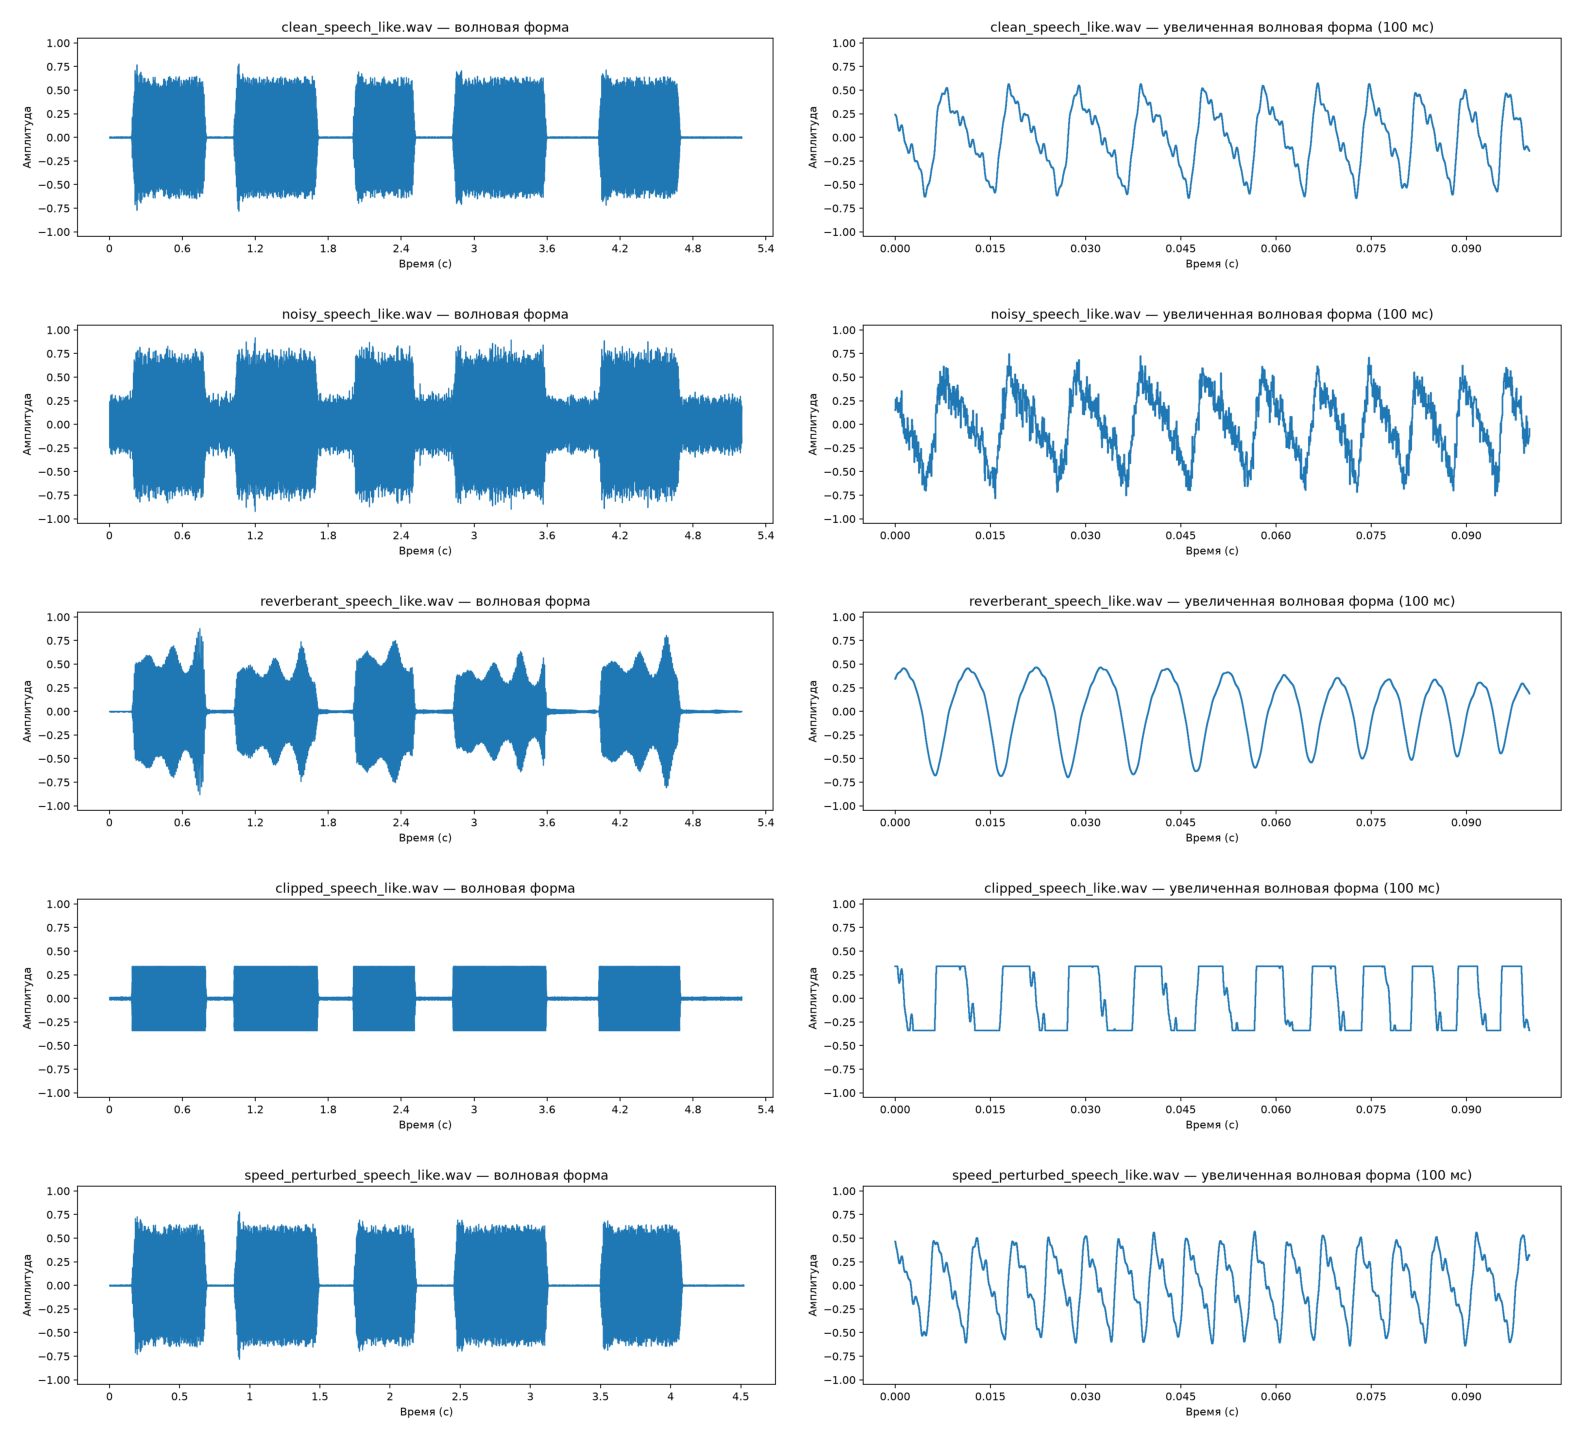

In [25]:
def show_plots(suffix, names=NAMES, row_height=3.6):
    fig, axes = plt.subplots(len(names), 1, figsize=(10, row_height * len(names)))
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        ax.imshow(mpimg.imread(OUT_DIR / f"{Path(name).stem}_{suffix}.png"))
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def show_pairs(left, right, names=NAMES, row_height=2.9):
    fig, axes = plt.subplots(len(names), 2, figsize=(16, row_height * len(names)))
    axes = np.atleast_2d(axes)
    for row, name in zip(axes, names):
        for ax, suffix in zip(row, (left, right)):
            ax.imshow(mpimg.imread(OUT_DIR / f"{Path(name).stem}_{suffix}.png"))
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_pairs("waveform", "waveform_zoom")

1. Какое искажение легче всего увидеть на волновой форме?
> клиппинг, потому что сегменты стали прямоугольными блоками.
2. Как выглядит клиппинг?
> как плоские плато на ±0.3.
3. Почему одной амплитуды может быть недостаточно, чтобы понять содержание речи?
> огибающая мб одинаковой у сигналов с разной природой и частотным составом, поэтому кроме осциллограммы строят ещё спектрограмму, например.

## часть D. лог-спектрограмма STFT

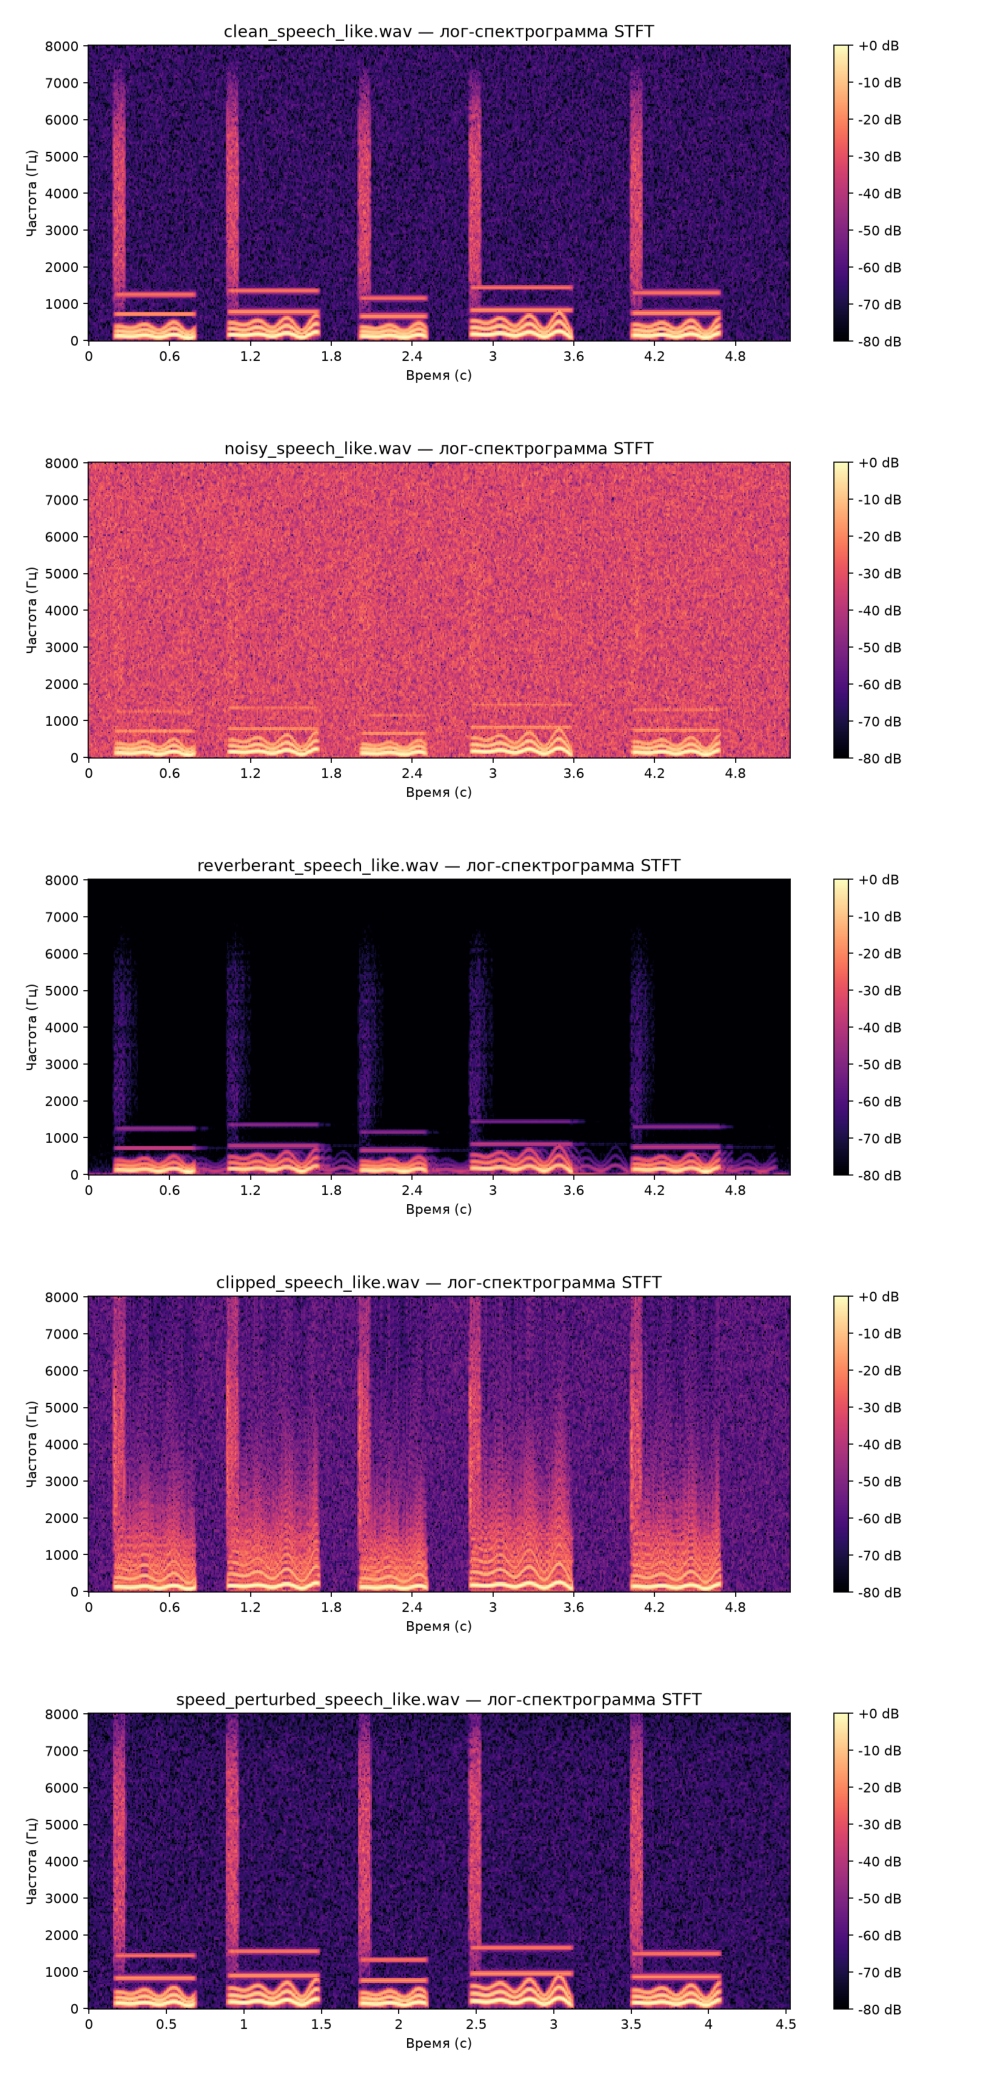

In [26]:
show_plots("stft_spectrogram", row_height=4.2)

In [27]:
def band_share(audio, sr, low_hz):
    power = np.abs(librosa.stft(audio, n_fft=lab.N_FFT, hop_length=lab.HOP_LENGTH, win_length=lab.WIN_LENGTH)) ** 2
    freqs = librosa.fft_frequencies(sr=sr, n_fft=lab.N_FFT)
    return float(power[freqs >= low_hz].sum() / power.sum())


def pause_rms(audio, sr, speed=1.0, start_s=0.82, end_s=1.0):
    start = int(start_s / speed * sr)
    end = int(end_s / speed * sr)
    return float(np.sqrt(np.mean(audio[start:end] ** 2)))


SPEED = {"speed_perturbed_speech_like.wav": 1.15}
metrics = pd.DataFrame(
    {
        "доля энергии выше 4 кГц": {n: band_share(a, sr, 4000) for n, (a, sr) in audio_data.items()},
        "rms в паузе 0.82–1.0 с": {n: pause_rms(a, sr, SPEED.get(n, 1.0)) for n, (a, sr) in audio_data.items()},
    }
)
metrics

,доля энергии выше 4 кГц,rms в паузе 0.82–1.0 с
clean_speech_like.wav,0.00190885,0.00221008
noisy_speech_like.wav,0.0706708,0.0964361
reverberant_speech_like.wav,4.04336e-06,0.00823782
clipped_speech_like.wav,0.00361766,0.00530413
speed_perturbed_speech_like.wav,0.00257634,0.00201595


1. В каком файле больше всего широкополосной высокочастотной энергии?
> у noisy, потому что это особенность белого шума - занять все частоты и спрятать истинный частотный состав.
2. Как реверберация меняет time-frequency паттерн?
> гармоники продолжаются после конца сегментов, их границы размыты. 
3. Почему шум может вызывать замены или удаления в ASR?
> потому что на фоне шума не видно полезного сигнала, и модель либо пропускает звук, либо принимает его за другой. + шум в паузах похож на речь.

## часть E. log-mel-спектрограмма

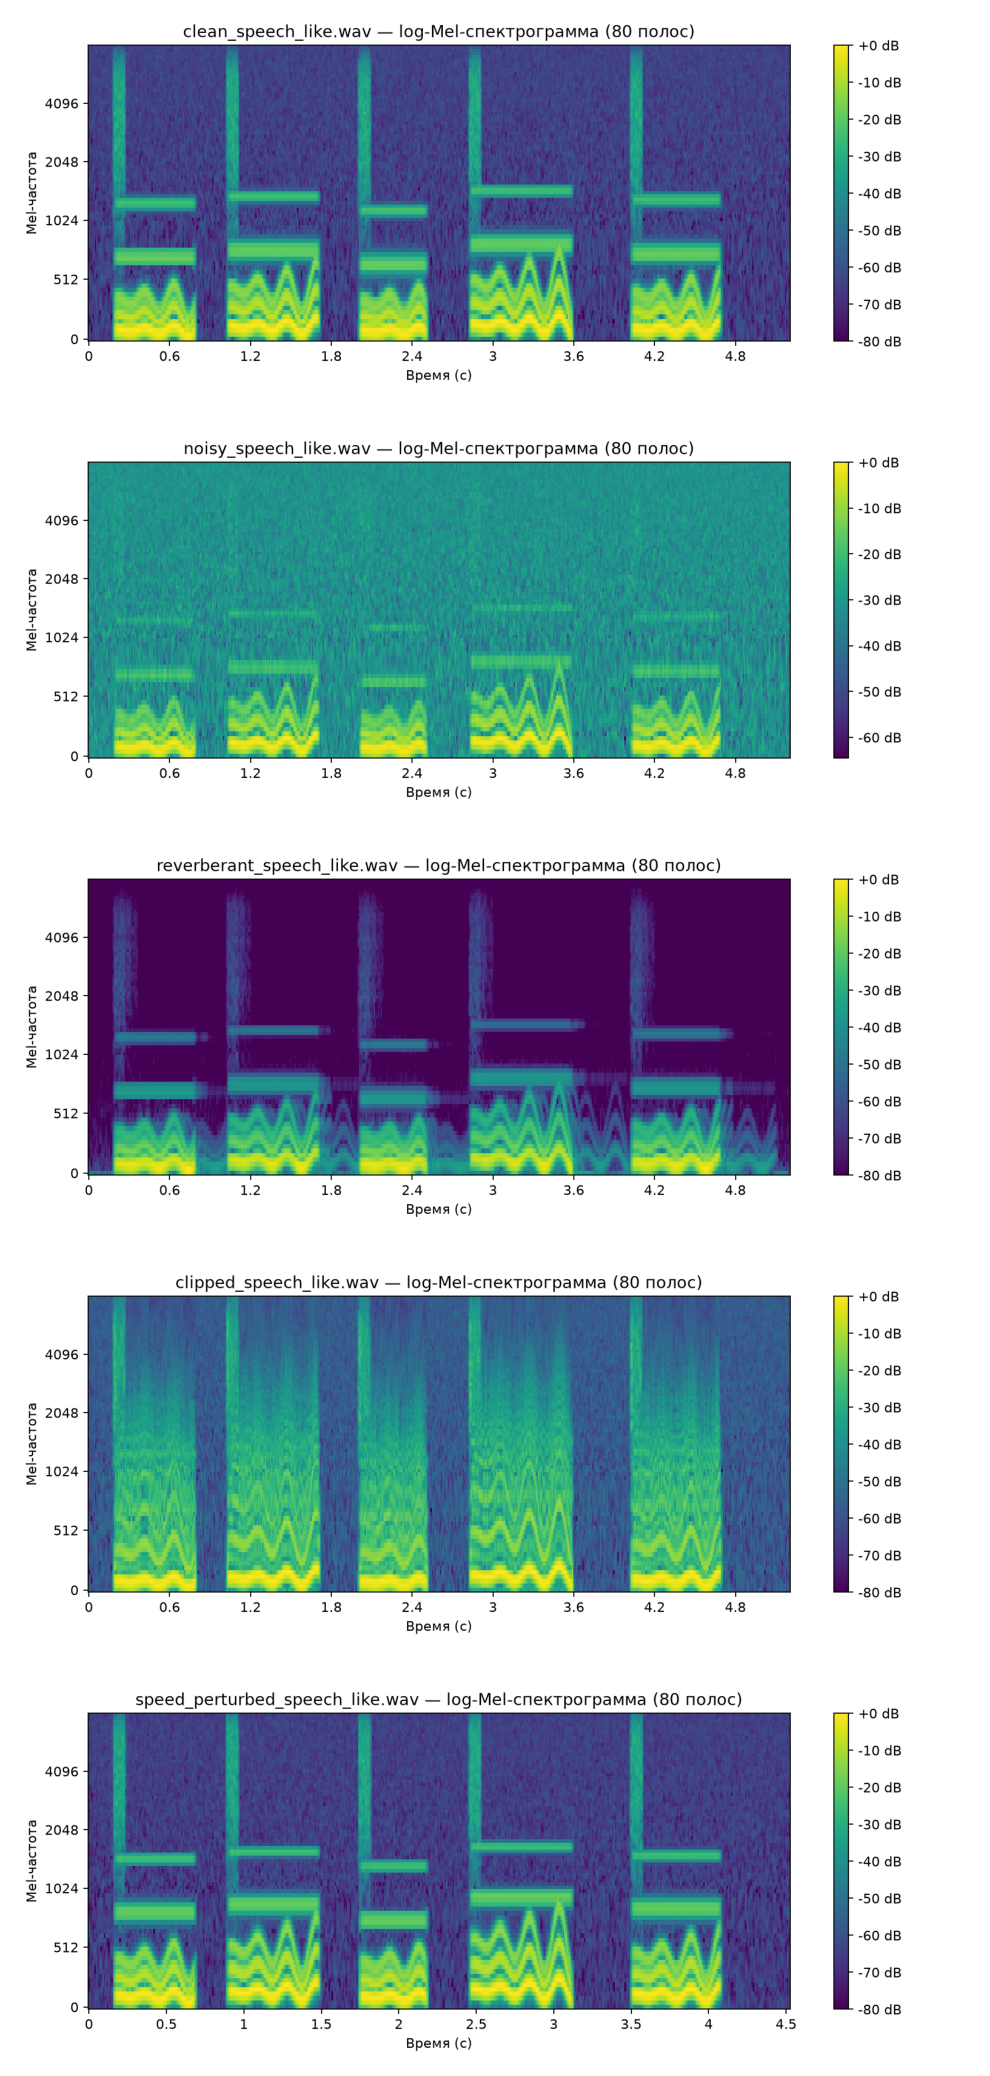

In [28]:
show_plots("log_mel", row_height=4.2)

In [29]:
audio, sr = audio_data["clean_speech_like.wav"]
stft = librosa.stft(audio, n_fft=lab.N_FFT, hop_length=lab.HOP_LENGTH, win_length=lab.WIN_LENGTH)
log_mel = lab.compute_log_mel(audio, sr)
mfcc = librosa.feature.mfcc(
    y=audio, sr=sr, n_mfcc=lab.N_MFCC, n_fft=lab.N_FFT, hop_length=lab.HOP_LENGTH,
    win_length=lab.WIN_LENGTH, n_mels=lab.N_MELS, fmin=lab.FMIN, fmax=lab.FMAX,
)
pd.DataFrame(
    {"stft": stft.shape, "log-mel": log_mel.shape, "mfcc": mfcc.shape},
    index=["признаки", "кадры"],
)

,stft,log-mel,mfcc
признаки,201,80,13
кадры,521,521,521


1. Какую информацию легче увидеть на log-Mel, чем на волновой форме?
> шумовые всплески в начале сегмента, форманты и гармоники.
2. Какая информация теряется или сжимается по сравнению с линейно-частотной STFT?
> частотное разрешение на высоких частотах из-за особенности функции логарифма.
3. Почему логарифмические энергии полезны для речи?
> позволяет видеть небольшие изменения в низкочастотном диапазоне.

## часть F. MFCC

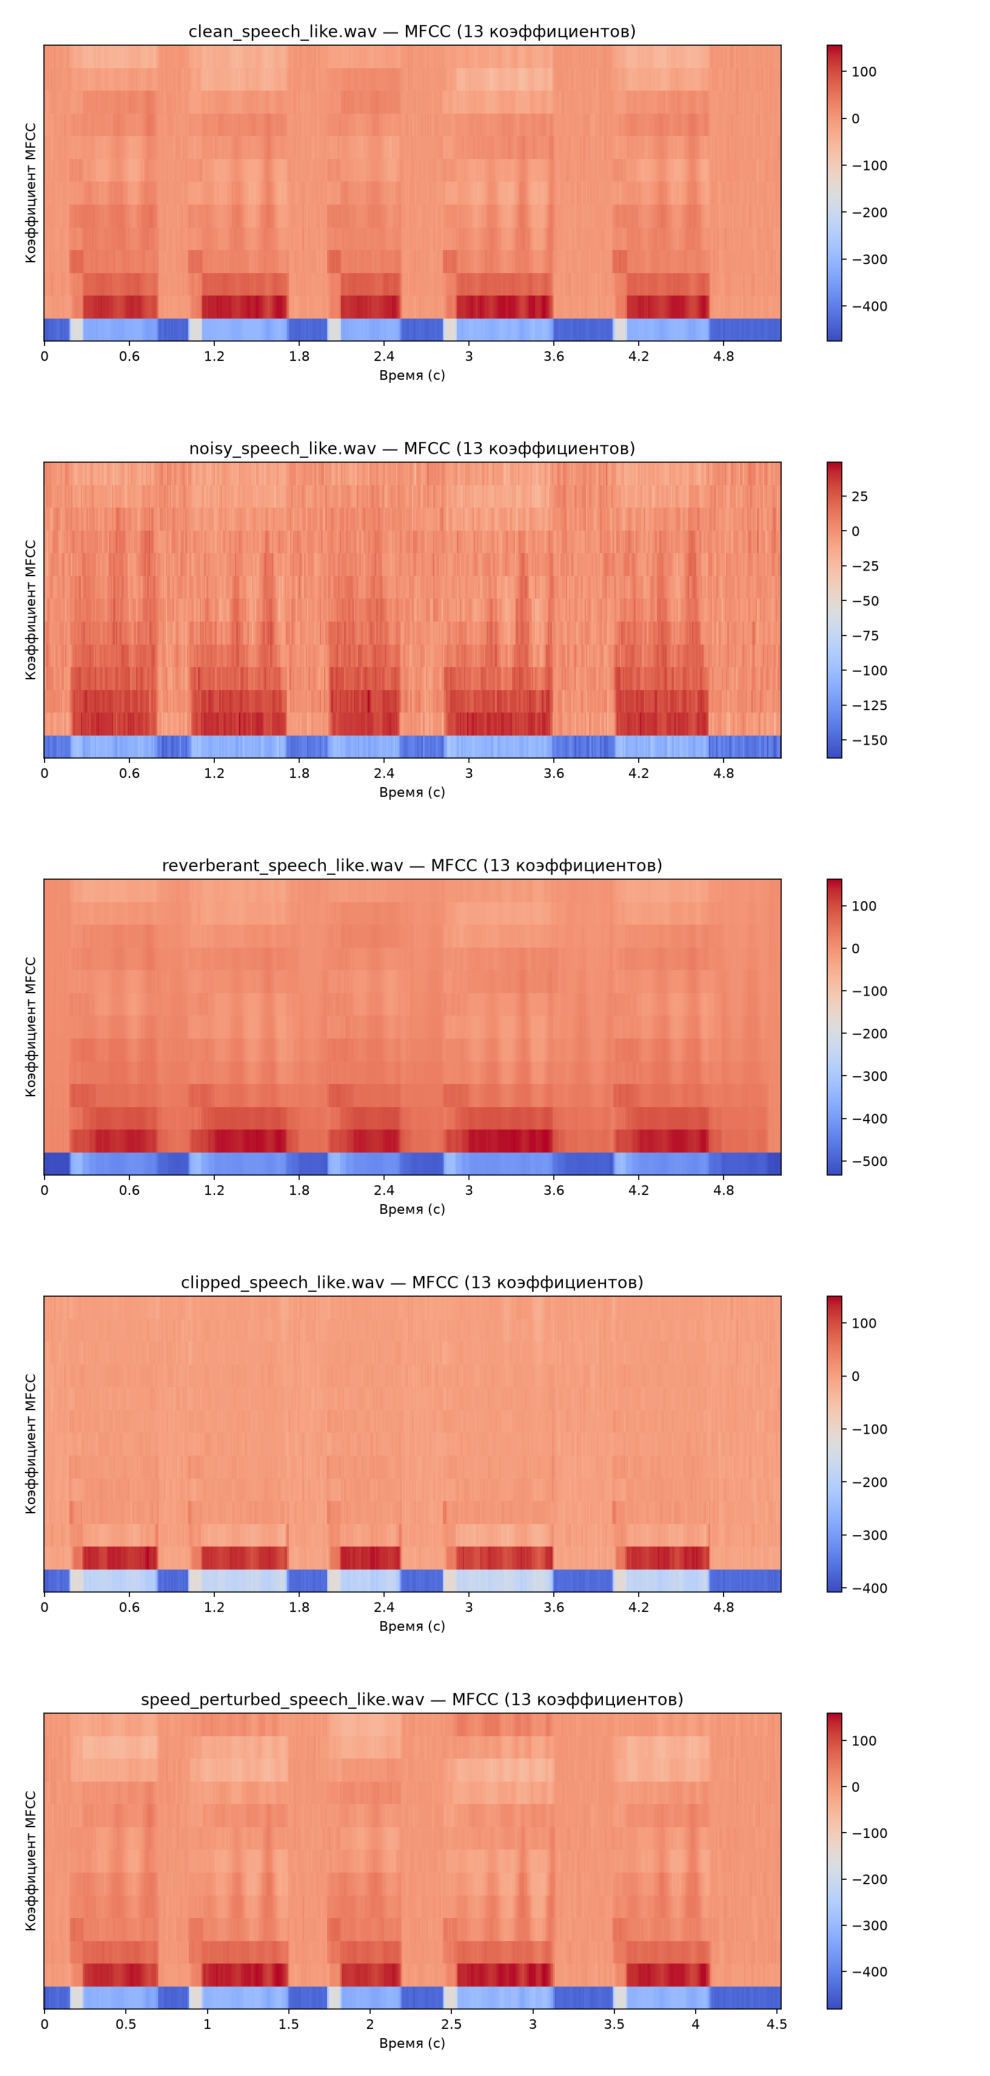

In [30]:
show_plots("mfcc", row_height=4.2)

1. Чем визуально графики MFCC отличаются от log-Mel?
> у mfcc нет оси частот, не различить гармоники, форманты и всплески
2. Почему компактное представление может быть полезным?
> потому что хранит полезную информацию более концентрировано. 
3. Почему современный нейросетевой ASR может предпочитать более богатые log-Mel признаки?
> потому что нейросеть проще самостоятельно сжать информацию в эмбеддинг, чем пользоваться универсальным компактным представлением.

## часть G. сравнение чистого и искажённого аудио

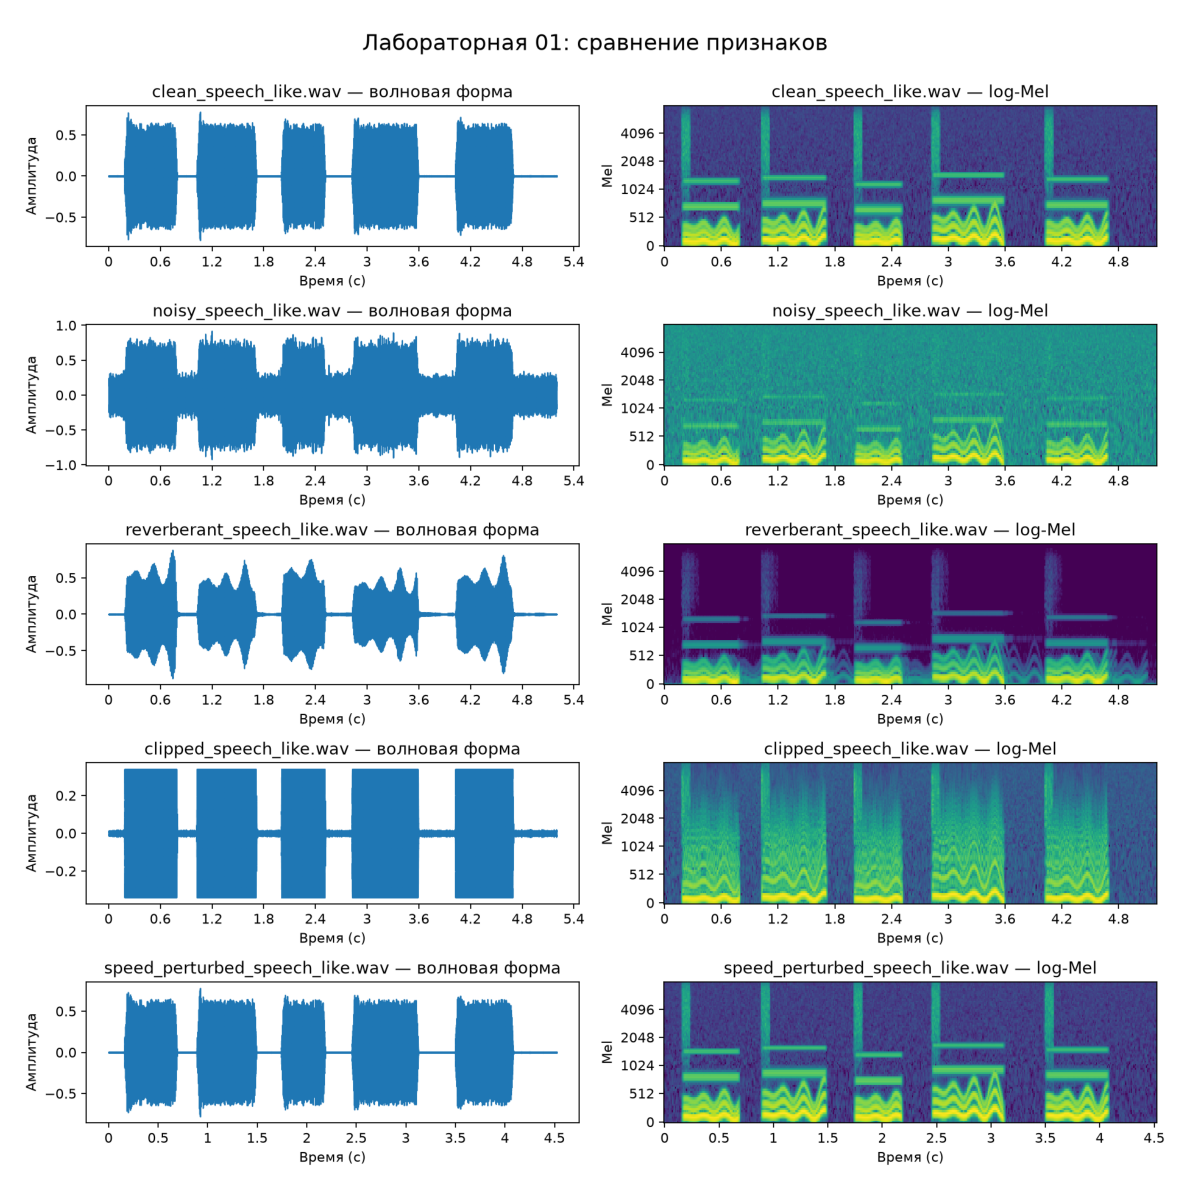

In [31]:
fig = plt.figure(figsize=(12, 13))
plt.imshow(mpimg.imread(OUT_DIR / "feature_comparison_contact_sheet.png"))
plt.axis("off")
plt.tight_layout()
plt.show()

| искажение | что изменилось в волновой форме | что изменилось в спектрограмме и log-mel | возможный тип ошибки ASR |
|---|---|---|---|
| шум | паузы заполнены фоном ±0.3, на увеличенном графике гармоники покрыты мелкой щетиной, пик 0.92 | энергия на всех частотах и во всех кадрах (7.1% выше 4 кГц), структура видна только ниже примерно 1.5 кГц, паузы на высоких полосах неотличимы от речи | замены и удаления слабых согласных, вставки и галлюцинации на паузах, плохие границы речи |
| реверберация | форма сглажена до почти синусоиды, внутри сегментов горбы амплитуды, небольшие хвосты в паузах (rms в паузе ×3.7) | всплески почти исчезли, гармоники тянутся за концы сегментов, переходы размыты | неверные временные метки и границы речи, удаления согласных, замены на стыках слов |
| клиппинг | меандр на ±0.34, 46% отсчётов на пределе | гармоники разной высоты в пределах каждого сегмента вплоть до 8 кГц, формантные полосы теряются, старшие mfcc почти однородны | замены на искажённых гласных, общее падение точности |
| ускорение | короче на 13% (4.52 с), сегменты и паузы короче, период колебаний короче | картина сжата по времени и сдвинута вверх по частоте на 15% (форманта 1250 → около 1440 Гц) | удаления коротких слов, замены из-за сдвинутых формант, сбой временных меток относительно разметки |

## дополнительное задание

In [ ]:
voice = WAV_DIR / "voice.wav"
print("исходный файл:", librosa.get_samplerate(voice), "Гц,", round(librosa.get_duration(path=voice), 2), "с")

audio_k, sr_k = librosa.load(voice, sr=lab.SAMPLE_RATE, mono=True, offset=4.0, duration=10.0)
audio_k = audio_k.astype(np.float32)
print("вырезка:", round(len(audio_k) / sr_k, 2), "с,", sr_k, "Гц")
Audio(audio_k, rate=sr_k)

исходный файл: 48000 Гц, 43.86 с
вырезка: 10.0 с, 16000 Гц


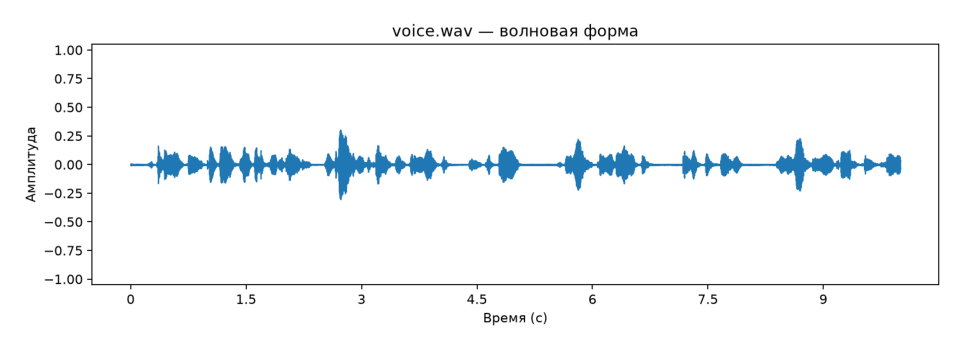

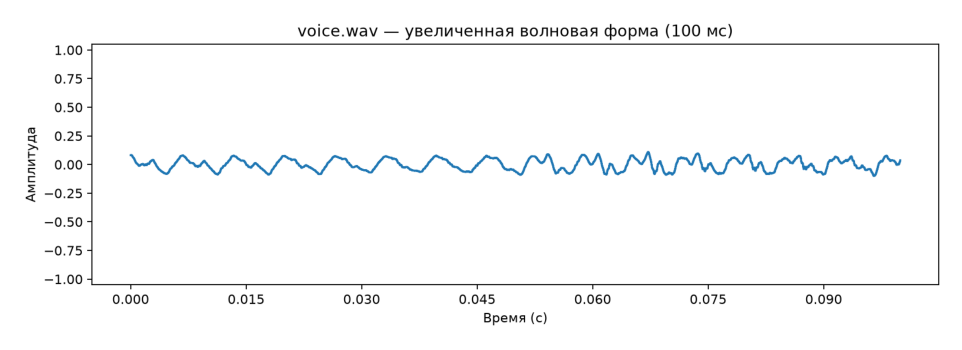

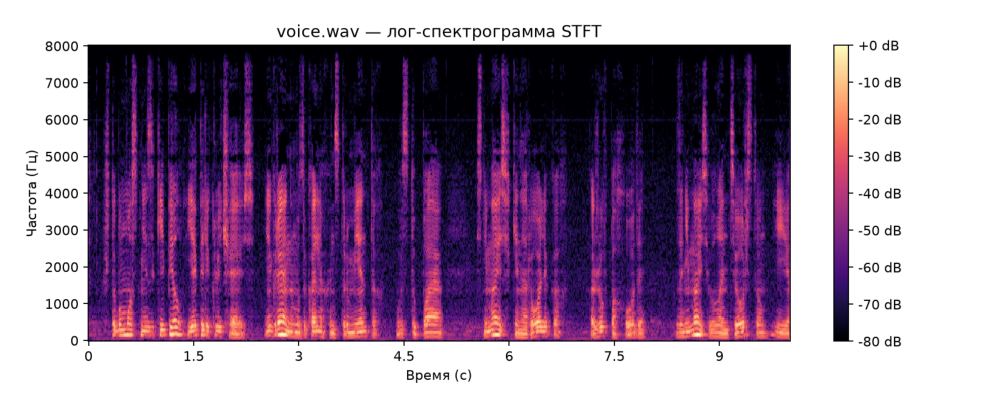

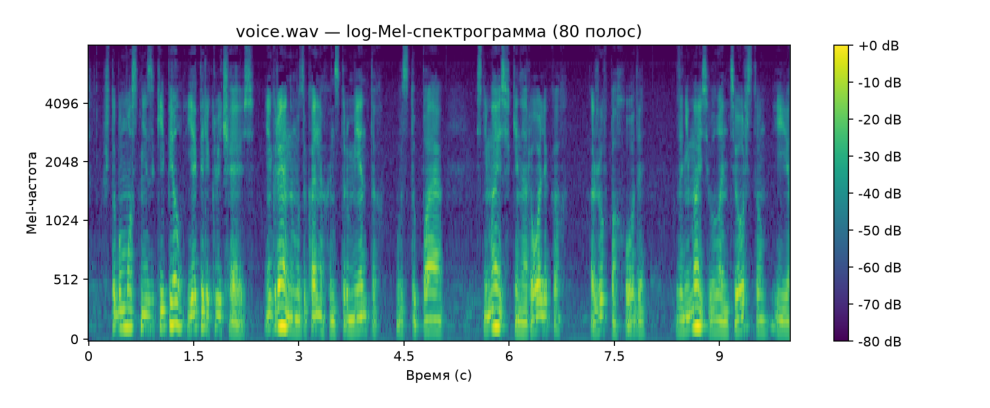

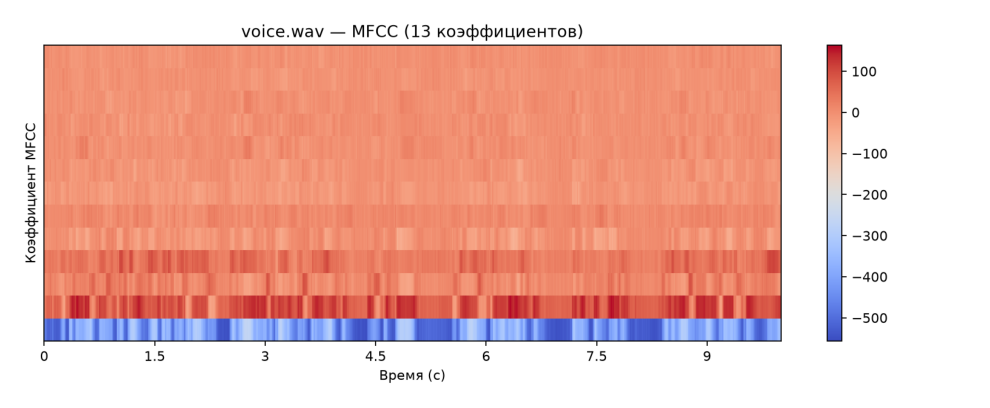

In [34]:
K_NAME = "voice.wav"
K_STEM = Path(K_NAME).stem
lab.save_waveform(audio_k, sr_k, K_NAME, OUT_DIR / f"{K_STEM}_waveform.png")
lab.save_waveform(audio_k, sr_k, K_NAME, OUT_DIR / f"{K_STEM}_waveform_zoom.png", zoom=True)
lab.save_stft_spectrogram(audio_k, sr_k, K_NAME, OUT_DIR / f"{K_STEM}_stft_spectrogram.png")
lab.save_log_mel(audio_k, sr_k, K_NAME, OUT_DIR / f"{K_STEM}_log_mel.png")
lab.save_mfcc(audio_k, sr_k, K_NAME, OUT_DIR / f"{K_STEM}_mfcc.png")

for suffix, height in [("waveform", 3.6), ("waveform_zoom", 3.6), ("stft_spectrogram", 4.2), ("log_mel", 4.2), ("mfcc", 4.2)]:
    show_plots(suffix, names=[K_NAME], row_height=height)

In [ ]:
clean_name = "clean_speech_like.wav"
noisy_name = "noisy_speech_like.wav"


def describe(name, audio, sr):
    row = lab.summarize_audio(name, audio, sr)
    row["доля энергии выше 4 кГц"] = band_share(audio, sr, 4000)
    return row


compare = pd.DataFrame(
    [
        describe("clean", *audio_data[clean_name]),
        describe("noisy", *audio_data[noisy_name]),
        describe("voice_10s", audio_k, sr_k),
    ]
).set_index("filename")
compare

,sample_rate_hz,duration_s,num_samples,peak_amplitude,rms,silence_fraction,clipping_fraction,доля энергии выше 4 кГц
filename,,,,,,,,
clean,16000,5.2,83200,0.780029,0.250151,0.38893,2.4e-05,0.00190885
noisy,16000,5.2,83200,0.920013,0.265441,0.0772,1.2e-05,0.0706708
kalimba_10s,16000,10,160000,0.549759,0.1216,0.150531,6e-06,0.00156487


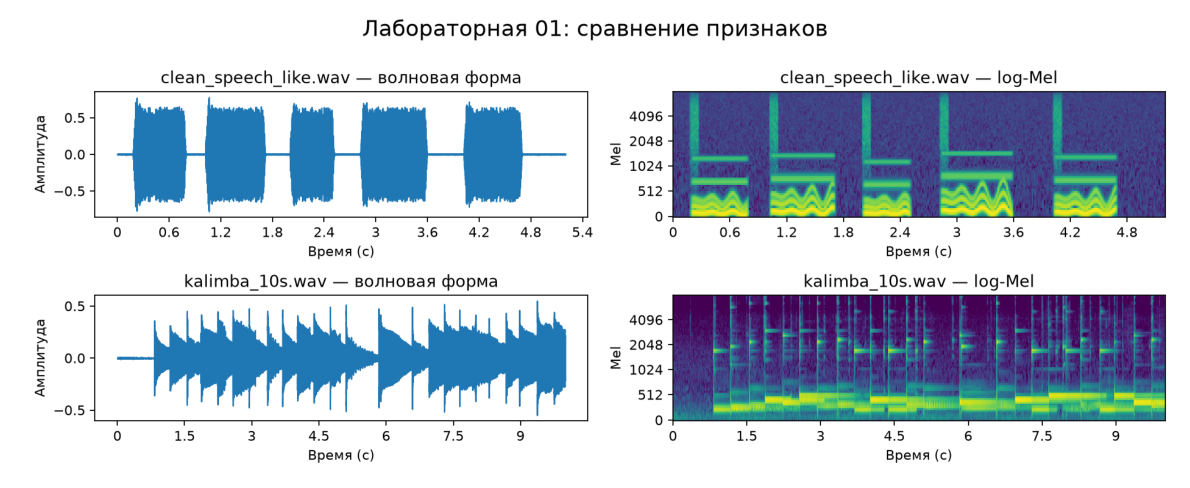

In [ ]:
lab.save_contact_sheet(
    [(clean_name, *audio_data[clean_name]), (K_NAME, audio_k, sr_k)],
    OUT_DIR / "voice_vs_clean_contact_sheet.png",
)
fig = plt.figure(figsize=(12, 6))
plt.imshow(mpimg.imread(OUT_DIR / "voice_vs_clean_contact_sheet.png"))
plt.axis("off")
plt.tight_layout()

plt.show()

сравнение с синтезированными аудио:
1. синтетика одинаково громкая во всех кусках, а в голосе громкие звуки чередуются с тихими.
2. в синтетике все блоки одинаковые с резкими паузами. в голосе паузы короче и граница между речью и тишиной менее резкая.
3. в синтетике высота тона и полосы формант стоят на месте. в голосе меняются.